# Task 3 -- Ablation matrix

Each row adds or removes one kind of information relative to its neighbour,
so a change in score can be attributed. The rows are fitted by
`src/ablation.py`; run it first to produce the `results/ablation_*.csv` files.

    python src/ablation.py --build-raw   # once; needs data/embeddings/ (C-raw only)
    python src/ablation.py

| Row | Features | Question |
|---|---|---|
| A | rates only | time-series baseline |
| B | rates + Task 2 lexicons | does basic NLP help? |
| C1 / C2 | rates + GloVe / FastText axes | static embeddings |
| C3 / C4 | rates + FinBERT / SBERT axes | contextual; domain vs general |
| C-fbs | rates + FinBERT sentiment | why not just FinBERT sentiment? |
| C-raw | rates + PCA of raw embeddings (best encoder) | do axes beat dumping vectors? |
| C5 | best C + novelty and concentration | does news surprise add signal? |
| C6 / C6-stack | late fusion with / without the novelty gate | fusion strategy |
| drop-* | C5 minus one channel | which channel matters |

**Selection.** Every row picks its model family (logistic regression or
XGBoost), hyperparameters and decay half-life on validation macro-F1. "Best
encoder" is the C1-C4 row with the best validation macro-F1, so it can differ
by target. The test block is scored once.

**Uncertainty.** With 176 test days a 0.02 MCC change is noise. Every row
reports MCC(row) - MCC(A) with a 95% circular block-bootstrap CI (10-session
blocks, 2,000 resamples, both models scored on the same resampled days).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
import viz

viz.apply_style()
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 60)
print("project root:", ROOT)

project root: C:\Users\lenovo\Documents\codng\nlp-project


In [2]:
from anchors import CHANNELS

metrics = pd.read_csv(config.ABLATION_METRICS_CSV)
boot = pd.read_csv(config.ABLATION_BOOTSTRAP_CSV)
TARGETS = ["direction", "large_move"]
ORDER = (["A", "B", "C1", "C2", "C3", "C4", "C-fbs", "C-raw", "C5", "C6", "C6-stack"]
         + [f"drop-{c}" for c in CHANNELS])
print(f"{metrics.row.nunique()} rows x {metrics.target.nunique()} targets")

18 rows x 2 targets


## 1. The matrix (test block)

In [3]:
cols = ["description", "encoder", "family", "decay_halflife", "accuracy", "f1_macro",
        "mcc", "roc_auc", "d_mcc", "ci_low", "ci_high", "p_gt0"]

def matrix(target):
    t = metrics[(metrics.target == target) & (metrics.split == "test")]
    t = t.merge(boot[boot.target == target], on=["target", "row"]).set_index("row")
    return t.reindex([r for r in ORDER if r in t.index])[cols].round(3)

matrix("direction")

,description,encoder,family,decay_halflife,accuracy,f1_macro,mcc,roc_auc,d_mcc,ci_low,ci_high,p_gt0
row,,,,,,,,,,,,
A,rates only,-,xgb,0,0.551,0.503,0.032,0.503,0.000,0.000,0.000,0.000
B,rates + Task 2 lexicons,-,xgb,0,0.562,0.535,0.078,0.543,0.046,-0.138,0.258,0.682
C1,rates + glove axes,glove,logreg,1,0.574,0.520,0.078,0.503,0.046,-0.100,0.204,0.720
C2,rates + fasttext axes,fasttext,xgb,2,0.523,0.481,-0.022,0.519,-0.054,-0.231,0.129,0.290
C3,rates + finbert axes,finbert,xgb,2,0.511,0.504,0.008,0.532,-0.024,-0.166,0.123,0.378
C4,rates + sbert axes,sbert,xgb,3,0.580,0.572,0.144,0.566,0.112,-0.044,0.279,0.908
C-fbs,rates + FinBERT sentiment,finbert,xgb,3,0.523,0.491,-0.009,0.524,-0.042,-0.204,0.117,0.295
C-raw,rates + PCA(16) of raw glove embeddings,glove,logreg,0,0.528,0.477,-0.020,0.528,-0.052,-0.229,0.117,0.272
C5,rates + glove axes + novelty,glove,xgb,0,0.500,0.483,-0.034,0.499,-0.066,-0.242,0.100,0.227


In [4]:
matrix("large_move")

,description,encoder,family,decay_halflife,accuracy,f1_macro,mcc,roc_auc,d_mcc,ci_low,ci_high,p_gt0
row,,,,,,,,,,,,
A,rates only,-,xgb,0,0.642,0.503,0.010,0.566,0.000,0.000,0.000,0.000
B,rates + Task 2 lexicons,-,xgb,0,0.756,0.522,0.079,0.579,0.069,-0.134,0.268,0.742
C1,rates + glove axes,glove,xgb,0,0.631,0.518,0.050,0.542,0.039,-0.054,0.135,0.788
C2,rates + fasttext axes,fasttext,xgb,5,0.670,0.554,0.115,0.609,0.105,-0.042,0.241,0.921
C3,rates + finbert axes,finbert,xgb,1,0.676,0.526,0.053,0.559,0.042,-0.102,0.178,0.711
C4,rates + sbert axes,sbert,xgb,0,0.653,0.527,0.060,0.605,0.049,-0.062,0.161,0.810
C-fbs,rates + FinBERT sentiment,finbert,xgb,0,0.665,0.527,0.056,0.559,0.046,-0.057,0.144,0.818
C-raw,rates + PCA(16) of raw fasttext embeddings,fasttext,xgb,0,0.659,0.538,0.084,0.565,0.074,-0.069,0.225,0.835
C5,rates + fasttext axes + novelty,fasttext,xgb,0,0.574,0.516,0.101,0.614,0.091,-0.055,0.256,0.872


## 2. MCC difference against Model A

A dot right of zero beats the rates-only baseline on the test block. The bar is
the 95% block-bootstrap CI of that difference; a bar that crosses zero is not
distinguishable from no effect.

findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.


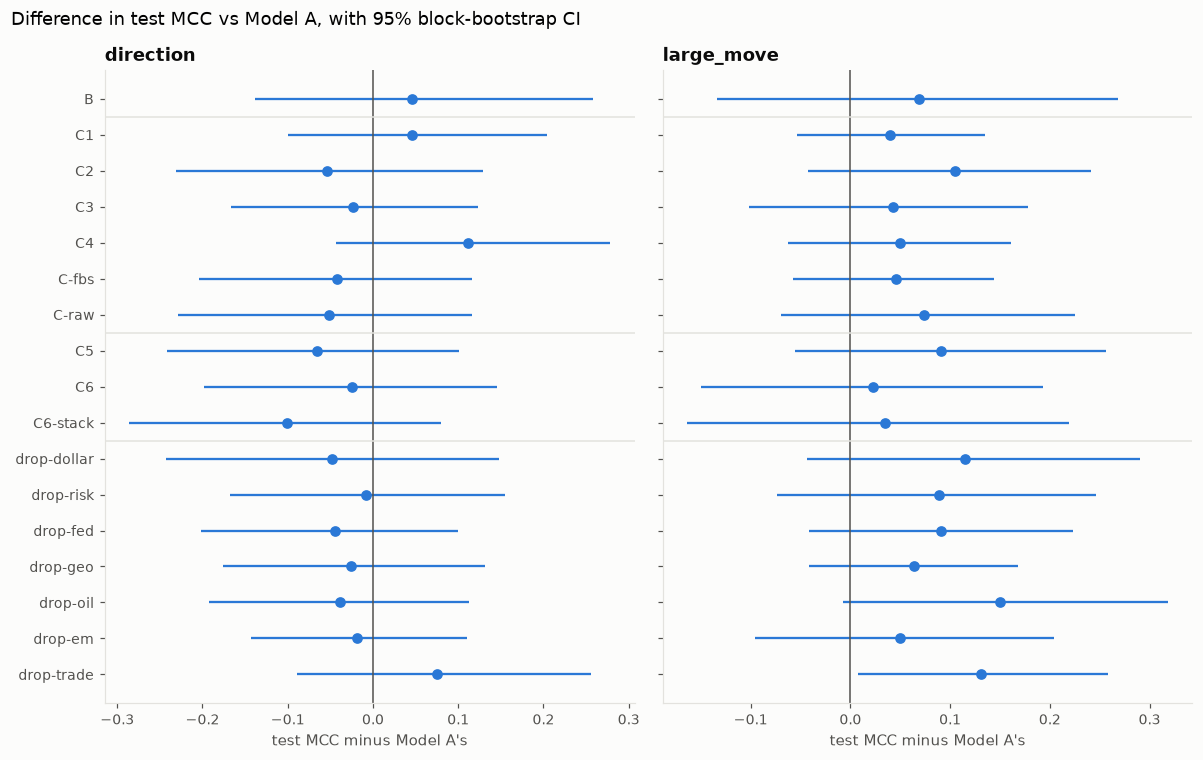

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 7), sharey=True)
rows = [r for r in ORDER if r != "A"]
ypos = {r: len(rows) - 1 - i for i, r in enumerate(rows)}
for ax, target in zip(axes, TARGETS):
    b = boot[(boot.target == target) & boot.row.isin(rows)]
    y = b.row.map(ypos)
    ax.errorbar(b.d_mcc, y, xerr=[b.d_mcc - b.ci_low, b.ci_high - b.d_mcc],
                fmt="o", color=viz.BLUE, ecolor=viz.BLUE, elinewidth=1.5,
                markersize=6, capsize=0)
    ax.axvline(0, color=viz.TEXT_SECONDARY, lw=1)
    for edge in ("C1", "C5", f"drop-{CHANNELS[0]}"):   # group separators
        ax.axhline(ypos[edge] + 0.5, color=viz.GRID, lw=1)
    ax.set_title(target)
    ax.set_xlabel("test MCC minus Model A's")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(list(ypos.values()), list(ypos.keys()))
fig.suptitle("Difference in test MCC vs Model A, with 95% block-bootstrap CI", x=0.01, ha="left")
plt.tight_layout()
plt.show()

## 3. Does validation predict test?

Every choice in the matrix (encoder, family, half-life) is made on validation.
If validation and test scores are unrelated, those choices are close to random.
Late-fusion rows are left out because their meta-model is fitted on
validation, so their validation scores are in-sample.

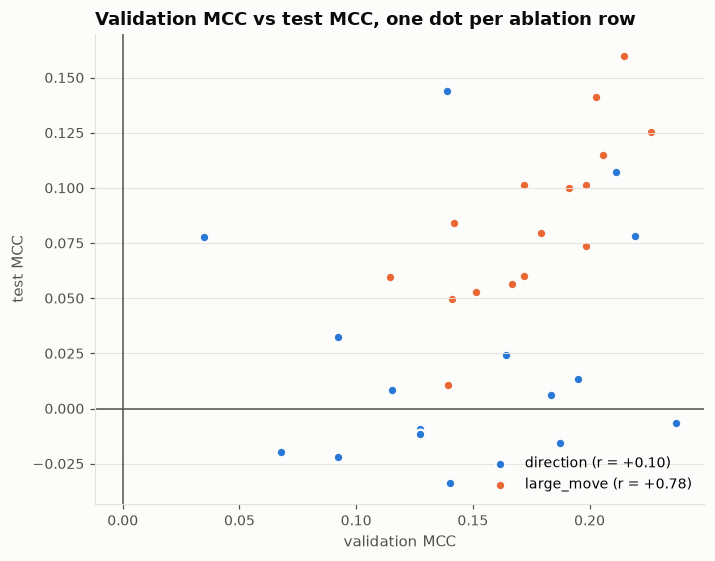

In [6]:
v = metrics[metrics.split == "validation"]
t = metrics[metrics.split == "test"]
m = v.merge(t, on=["target", "row"], suffixes=("_val", "_test"))
m = m[~m.val_in_sample_val]

fig, ax = plt.subplots(figsize=(6.6, 5.2))
for target, color in zip(TARGETS, [viz.BLUE, viz.ORANGE]):
    s = m[m.target == target]
    r = s[["mcc_val", "mcc_test"]].corr().iloc[0, 1]
    ax.scatter(s.mcc_val, s.mcc_test, s=40, color=color,
               edgecolor=viz.SURFACE, linewidth=1.5, label=f"{target} (r = {r:+.2f})")
ax.axhline(0, color=viz.TEXT_SECONDARY, lw=1)
ax.axvline(0, color=viz.TEXT_SECONDARY, lw=1)
ax.set_xlabel("validation MCC")
ax.set_ylabel("test MCC")
ax.set_title("Validation MCC vs test MCC, one dot per ablation row")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [7]:
# What validation chose, per target.
sel = (metrics[(metrics.split == "test") & metrics.row.isin(["A", "C1", "C2", "C3", "C4", "C5"])]
       [["target", "row", "encoder", "family", "decay_halflife", "params", "n_features"]])
sel.sort_values(["target", "row"]).reset_index(drop=True)

,target,row,encoder,family,decay_halflife,params,n_features
0,direction,A,-,xgb,0,"{""n_estimators"": 200, ""max_depth"": 2, ""learnin...",16
1,direction,C1,glove,logreg,1,"{""C"": 10.0}",30
2,direction,C2,fasttext,xgb,2,"{""n_estimators"": 400, ""max_depth"": 3, ""learnin...",30
3,direction,C3,finbert,xgb,2,"{""n_estimators"": 150, ""max_depth"": 4, ""learnin...",30
4,direction,C4,sbert,xgb,3,"{""n_estimators"": 150, ""max_depth"": 4, ""learnin...",30
5,direction,C5,glove,xgb,0,"{""n_estimators"": 150, ""max_depth"": 4, ""learnin...",33
6,large_move,A,-,xgb,0,"{""n_estimators"": 200, ""max_depth"": 2, ""learnin...",16
7,large_move,C1,glove,xgb,0,"{""n_estimators"": 200, ""max_depth"": 2, ""learnin...",30
8,large_move,C2,fasttext,xgb,5,"{""n_estimators"": 200, ""max_depth"": 2, ""learnin...",30
9,large_move,C3,finbert,xgb,1,"{""n_estimators"": 400, ""max_depth"": 3, ""learnin...",30


## 4. Which channel matters? (drop-one)

Change in test MCC when one channel's direction and attention scores are
removed from C5. A negative bar means the model got worse without the channel,
i.e. the channel was helping.

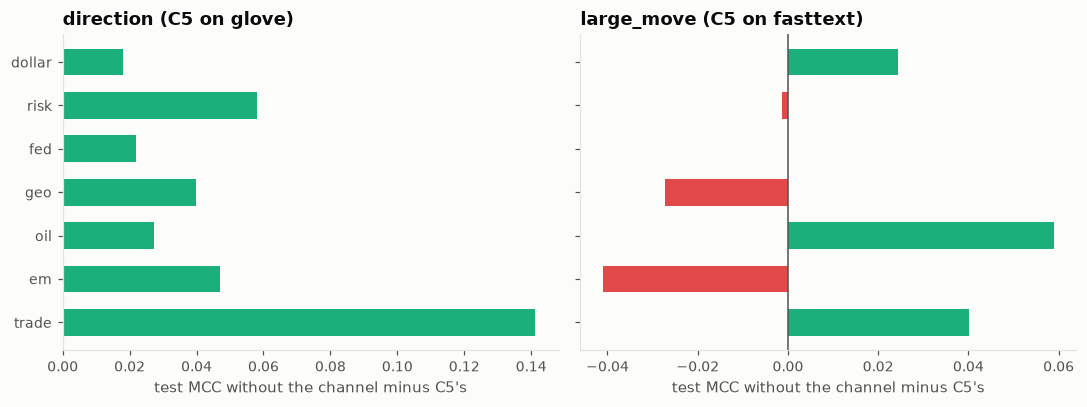

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, target in zip(axes, TARGETS):
    t = metrics[(metrics.target == target) & (metrics.split == "test")].set_index("row")
    d = pd.Series({c: t.loc[f"drop-{c}", "mcc"] - t.loc["C5", "mcc"] for c in CHANNELS})
    ax.barh(list(d.index)[::-1], d.values[::-1], height=0.62,
            color=[viz.COLOR_DOWN if x < 0 else viz.COLOR_UP for x in d.values[::-1]])
    ax.axvline(0, color=viz.TEXT_SECONDARY, lw=1)
    ax.set_title(f"{target} (C5 on {t.loc['C5', 'encoder']})")
    ax.set_xlabel("test MCC without the channel minus C5's")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 5. Findings

1. **No text row beats Model A on direction with a CI that excludes zero.** The
   largest gain is C4 (SBERT axes, +0.112, CI −0.044 to +0.279, ahead of A in
   91% of resamples). Validation picked GloVe as the best encoder for
   direction, so C5, C6 and the drop-one rows are built on GloVe. Of those,
   only drop-trade is ahead of A (+0.075, CI −0.089 to +0.256).

2. **For direction, validation does not predict test; for large moves, it
   does.** Across ablation rows, validation and test MCC correlate at
   r = +0.10 for direction and r = +0.78 for large moves (section 3). So the
   validation-based choices are close to random for direction, while the
   large-move results are more trustworthy.

3. **Large moves are where text looks most useful.** Every C1–C4 row is ahead
   of A in at least 71% of resamples, and C2 (FastText) gains +0.105 (CI
   −0.042 to +0.241). Model A itself is close to zero (MCC 0.010). This fits the
   literature: news predicts magnitude better than sign.

4. **Axes beat raw embeddings, but within noise.** For the encoder validation
   picked, the axes row is ahead of C-raw on both targets (direction +0.046 vs
   −0.052; large move +0.105 vs +0.074), with 17 or fewer interpretable
   features against up to 32 opaque ones.

5. **Novelty and the gate add nothing reliable.** C5 is below its best C on
   both targets. The gated C6 beats the ungated C6-stack on direction and loses
   on large moves.

6. **FinBERT sentiment is no better than the axes.** C-fbs is −0.042
   (direction) and +0.046 (large move), never ahead of the best axes row.

7. **Drop-one finds no channel that clearly carries the signal.** For
   direction, removing any one of the seven GloVe channels *raises* test MCC.
   For large moves (FastText), removing em or geo lowers it, and four others
   raise it. The single CI that excludes
   zero in the whole matrix is drop-trade on large moves (+0.131, CI +0.008 to
   +0.258): 1 of 34 comparisons, about what chance alone would give at the 95%
   level.

**Bottom line for the report.** The channel-axis features are a defensible,
interpretable representation, and the large-move target shows a consistent
positive tilt. But with 176 test days, no fusion or feature set is
statistically distinguishable from the rates-only baseline. Report it in
those words.